In [1]:
from xraydb import material_mu
import xraydb as xraydb
import numpy as np
import matplotlib.pyplot as plt
from xraydb import mu_elam
from xraydb import fluor_yield
from xraydb import ck_probability
from xraydb import atomic_number
import matplotlib.ticker as ticker
import scipy.integrate as integrate
from scipy.integrate import quad
from numpy import sin, cos, tan
import xrf_model
from xrf_model import *

a=-0.082 keV, b=68.117 eV/ch;  punti=(206, 13.95, 875, 59.52)


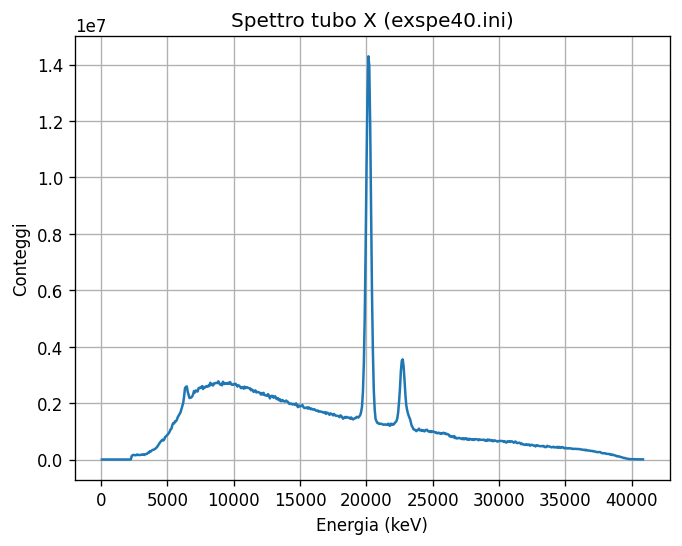

In [3]:
#X-ray tube spectrum -> .ini files
import numpy as np
import matplotlib.pyplot as plt
import re

def read_exspe(path):
    # leggi (UTF-16 tipico dei file XGLab)
    with open(path, 'r', encoding='utf-16') as f:
        lines = [ln.strip() for ln in f]

    def parse_point(s):
        ch_str, e_str = s.split()
        ch = int(ch_str)
        E = float(e_str.replace(',', '.'))
        return ch, E

    i_cal0 = lines.index('Coefficients points number = 2')
    ch1, E1 = parse_point(lines[i_cal0+1])
    ch2, E2 = parse_point(lines[i_cal0+2])

    # linear calibration Energy = a + b * channel
    b = (E2 - E1) / (ch2 - ch1)          # keV / channel
    a = E1 - b * ch1                      # keV

    # counts extraction
    i_data = lines.index('[DATA]') + 1
    counts = []
    for s in lines[i_data:]:
        if not s:
            continue
        # solo interi/float; le linee sono interi
        if re.fullmatch(r'[0-9]+', s):
            counts.append(int(s))
    counts = np.asarray(counts, dtype=float)

    channels = np.arange(len(counts))
    energy_keV = a + b * channels
    return energy_keV, counts, (a, b), (ch1, E1, ch2, E2)


E, C, (a,b), pts = read_exspe('exspe40.ini')
print(f"a={a:.3f} keV, b={b*1e3:.3f} eV/ch;  punti={pts}")

# optional: truncation of negative energies and above 40 keV
mask = E >= 0
E_plot, C_plot = E[mask]*1000, C[mask]
E_plot,C_plot=E_plot[:600],C_plot[:600]

plt.figure()
plt.plot(E_plot, C_plot)
plt.xlabel('Energy [eV]')
plt.ylabel('Counts')
plt.grid(True)
plt.show()

In [4]:
#optional: cut energies below the lightest element ionization edge
min_edge = 1559.0  

mask = E_plot >= min_edge
E_tube_eV = E_plot[mask]
I_tube    = C_plot[mask]

In [5]:
import numpy as np
import matplotlib.pyplot as plt

#rebinning of the spectral channels (if the source file has a different energy axis than the spectrometer) 
#-> the binning of the anode peak are preserved 

def compress_tube_spectrum_with_peaks(
    E_eV: np.ndarray,
    I: np.ndarray,
    peak_windows_eV,
    rel_thresh_cont: float = 1e-3,
    bin_width_cont_eV: float | None = None,
):

    E_eV = np.asarray(E_eV, dtype=float)
    I = np.asarray(I, dtype=float)
    assert E_eV.shape == I.shape

   
    peak_mask = np.zeros_like(E_eV, dtype=bool)
    for Emin, Emax in peak_windows_eV:
        peak_mask |= (E_eV >= Emin) & (E_eV <= Emax)

    
    if bin_width_cont_eV is None:
        dE_native = np.median(np.diff(E_eV))
        bin_width_cont_eV = 4.0 * dE_native

    I_max = I.max()
    thr = rel_thresh_cont * I_max

    E_out = []
    I_out = []

    i = 0
    N = len(E_eV)

    while i < N:
        if peak_mask[i]:
           
            E_out.append(E_eV[i])
            I_out.append(I[i])
            i += 1

        else:
            
            E_start = E_eV[i]
            E_bin = []
            I_bin = []

            while i < N and (not peak_mask[i]) and (E_eV[i] - E_start <= bin_width_cont_eV):
                E_bin.append(E_eV[i])
                I_bin.append(I[i])
                i += 1

            if not E_bin:
                continue

            E_bin = np.asarray(E_bin)
            I_bin = np.asarray(I_bin)

            I_sum = I_bin.sum()
            if I_sum > 0:
                E_bin_center = np.sum(E_bin * I_bin) / I_sum
            else:
                E_bin_center = E_bin.mean()

            I_bin_value = I_bin.mean()

            if I_bin_value < thr:
                pass

            E_out.append(E_bin_center)
            I_out.append(I_bin_value)

    E_out = np.asarray(E_out)
    I_out = np.asarray(I_out)

    order = np.argsort(E_out)
    return E_out[order], I_out[order]


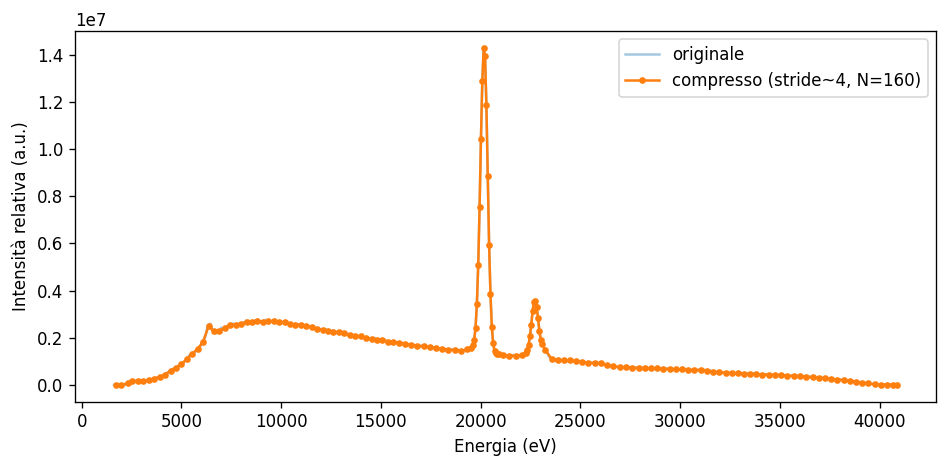

In [6]:
# Anode peaks energy windows (in eV)
peak_windows = [
    (20220 - 700, 20220 + 700),   # finestra Kα
    (22720 - 400, 22720 + 400),   # finestra Kβ
]

# passo nativo medio
dE_native = np.median(np.diff(E_tube_eV))

bin_width_cont = 4.0 * dE_native

E_eff, I_eff = compress_tube_spectrum_with_peaks(
    E_tube_eV, I_tube,
    peak_windows_eV=peak_windows,
    rel_thresh_cont=1e-3,
    bin_width_cont_eV=bin_width_cont
)

plt.figure(figsize=(8,4))
plt.plot(E_tube_eV, I_tube, alpha=0.4, label="originale")
plt.plot(E_eff, I_eff, "-o", ms=3, label=f"compresso (stride~4, N={len(E_eff)})")
plt.xlabel("Energia (eV)")
plt.ylabel("Intensità relativa (a.u.)")
plt.legend()
plt.tight_layout()
plt.show()


In [7]:
#area normalization

I=I_eff/np.sum(I_eff)
weights=I
E0=E_eff

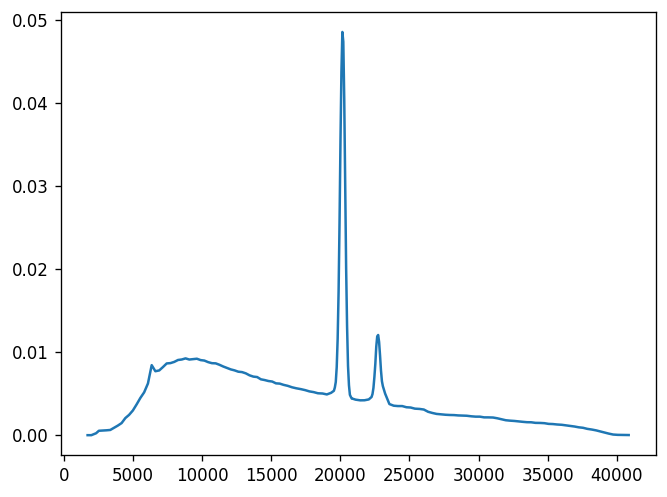

In [8]:
plt.plot(E0,weights)

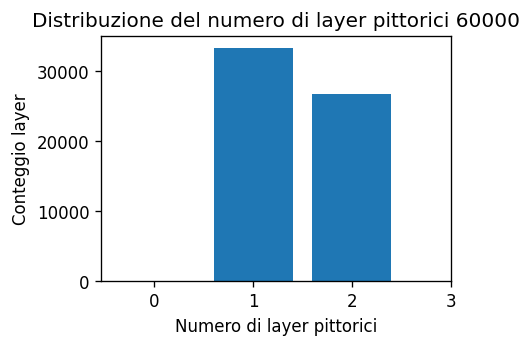

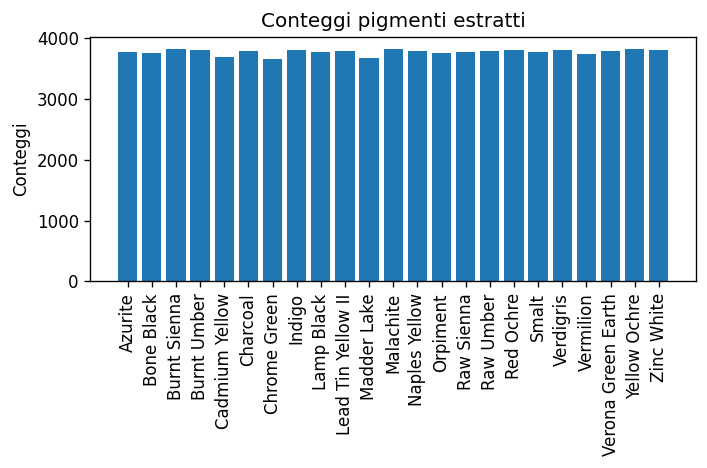

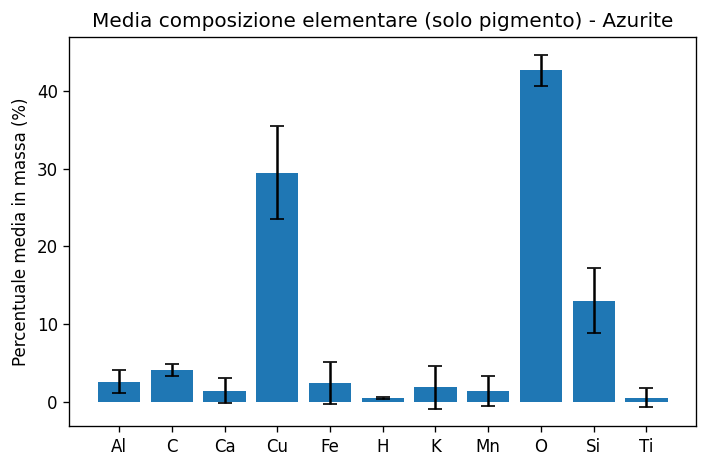

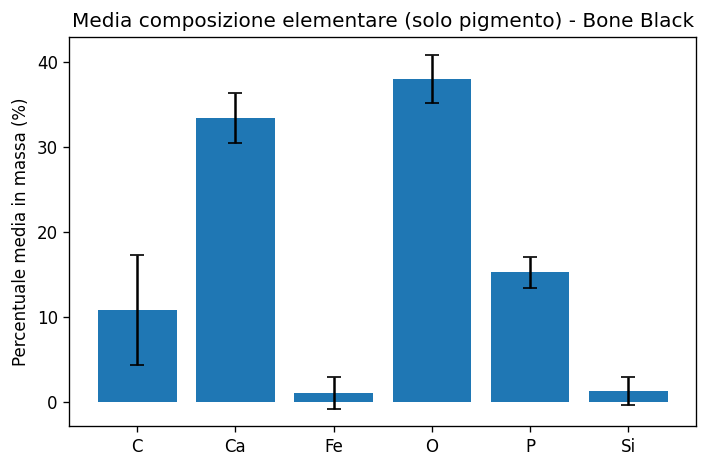

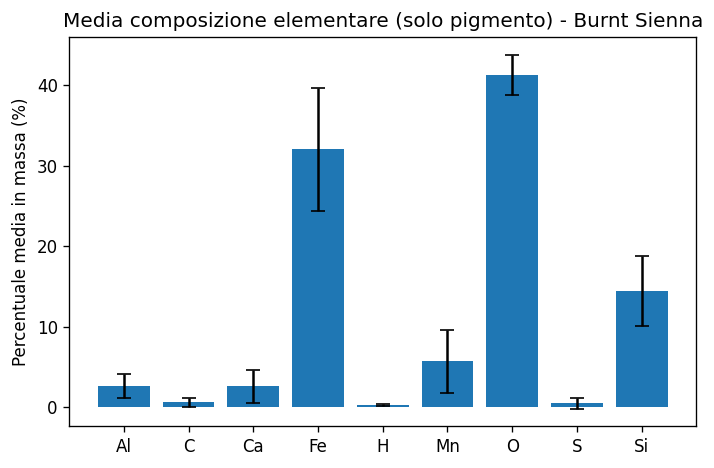

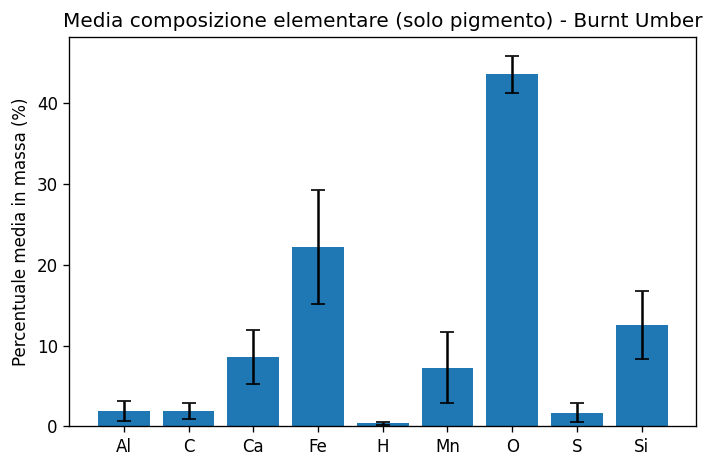

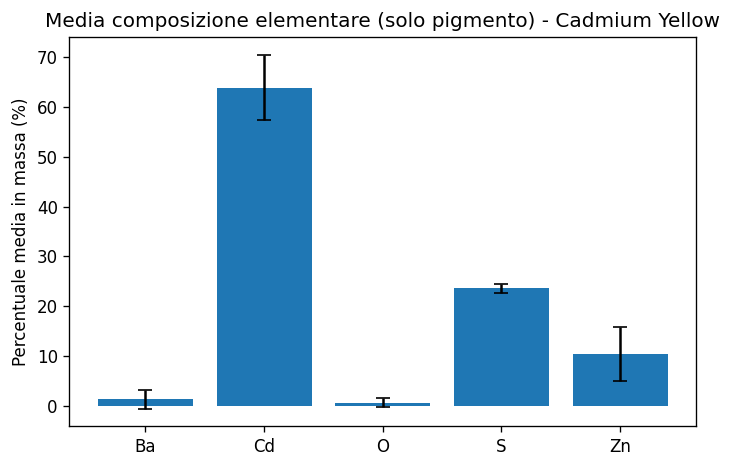

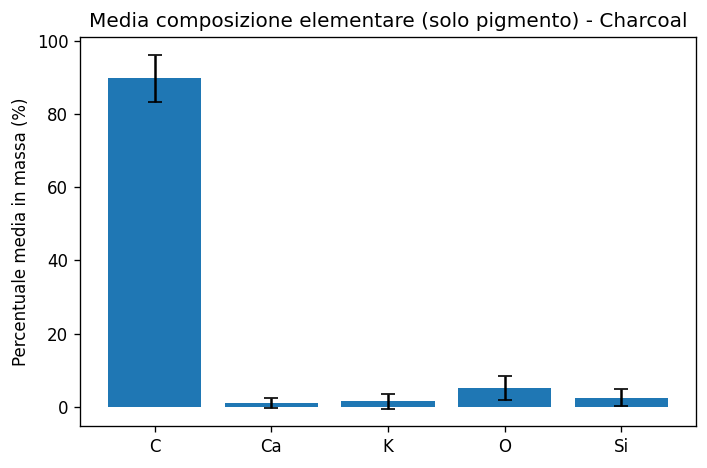

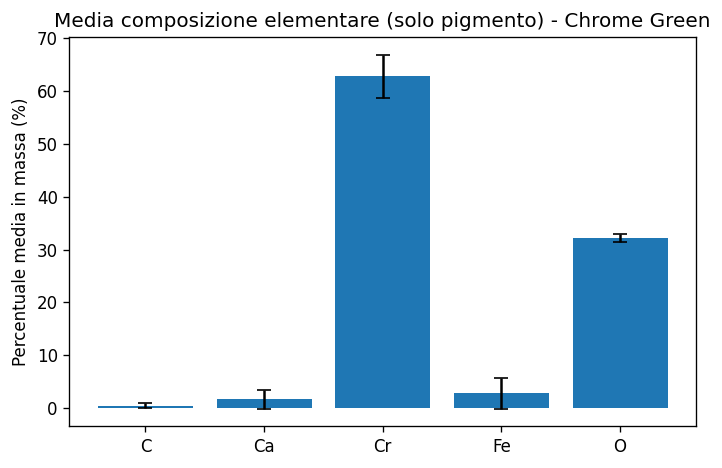

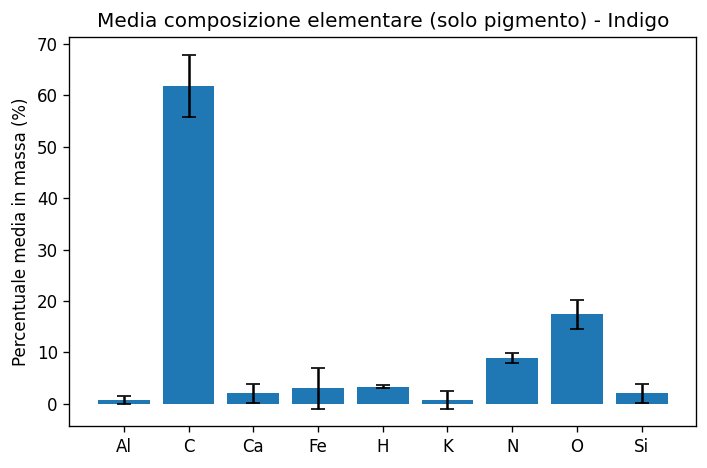

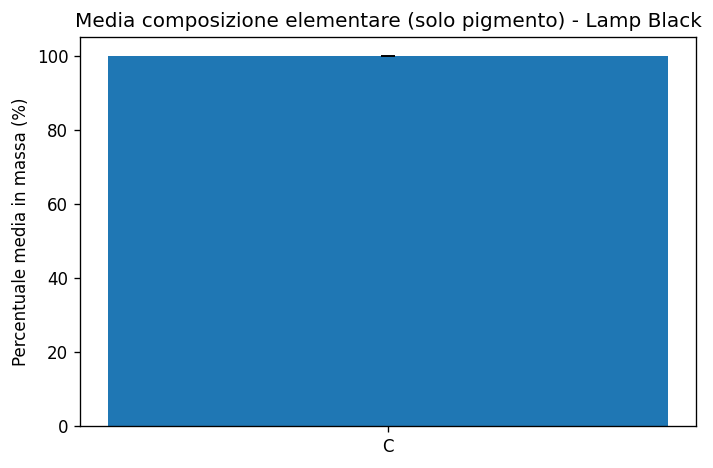

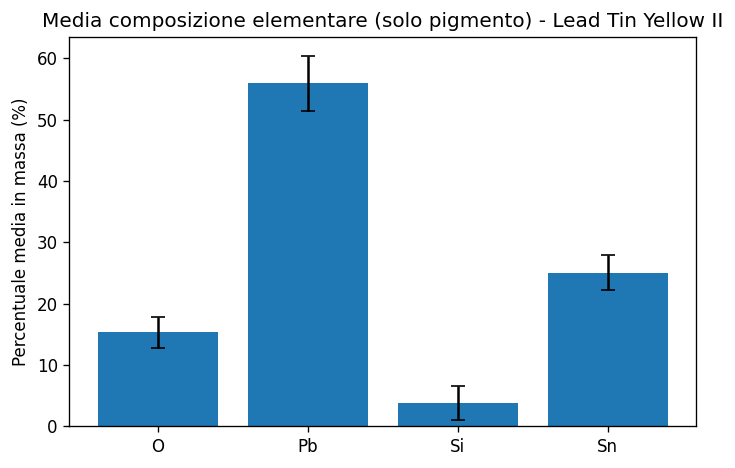

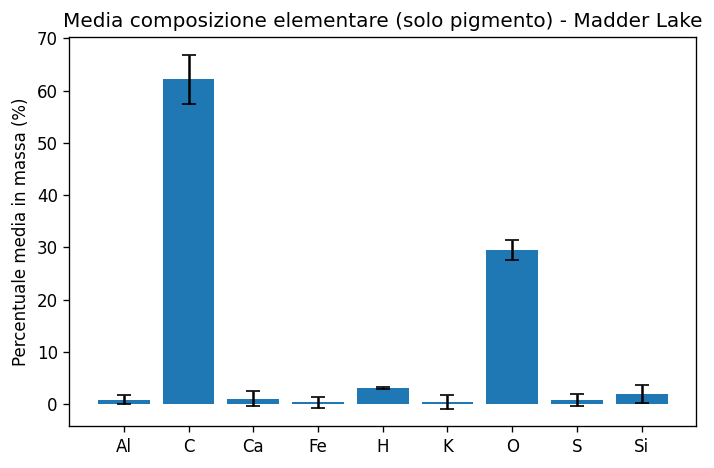

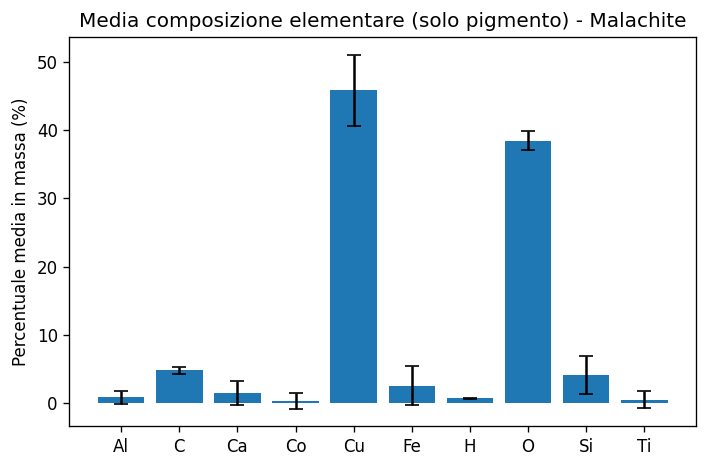

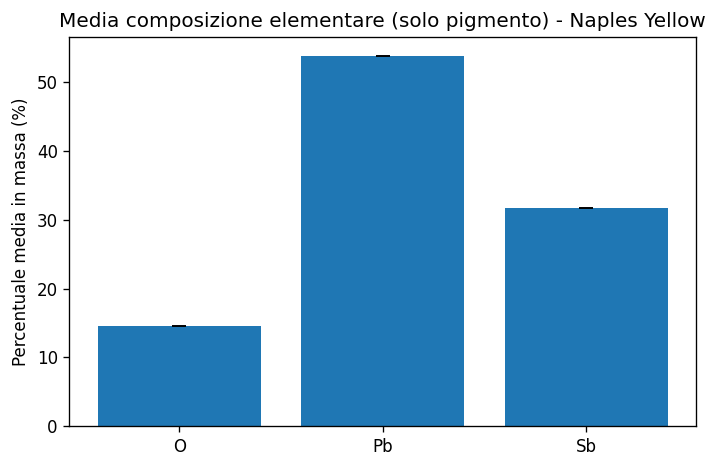

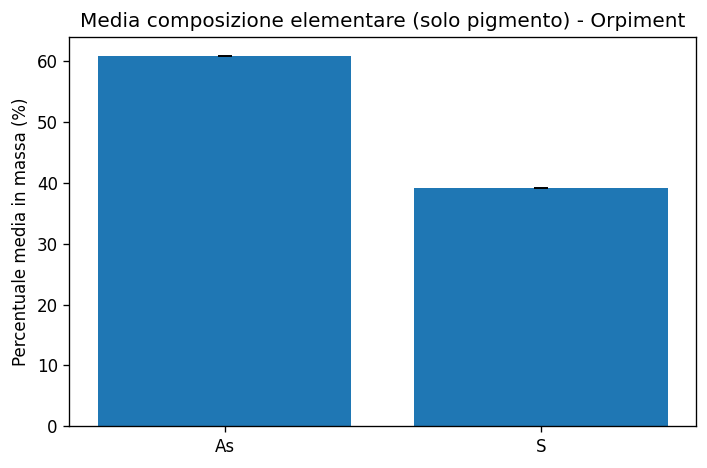

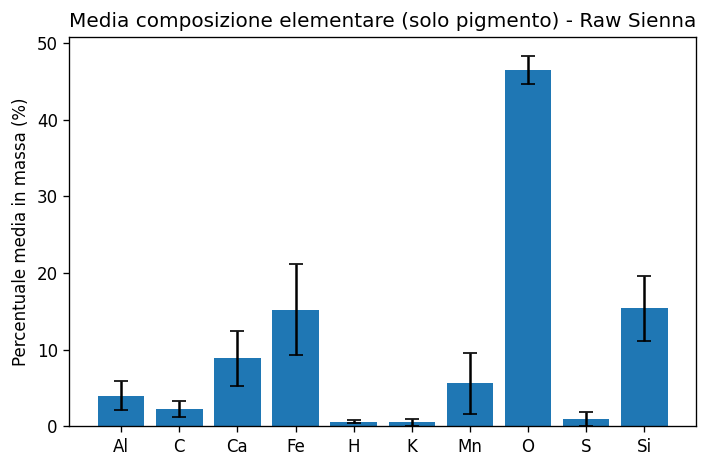

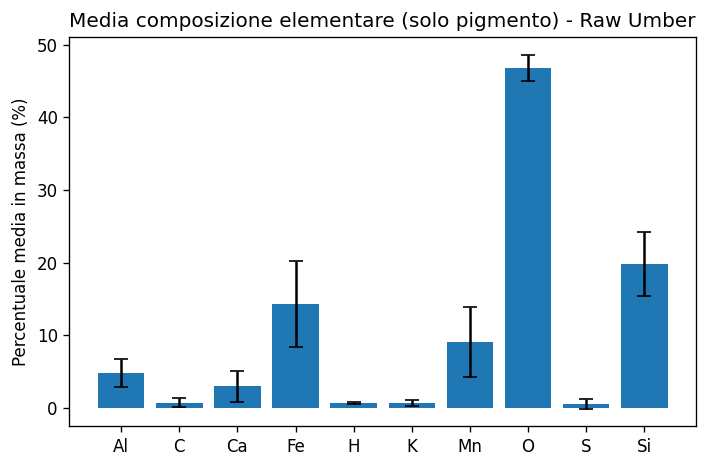

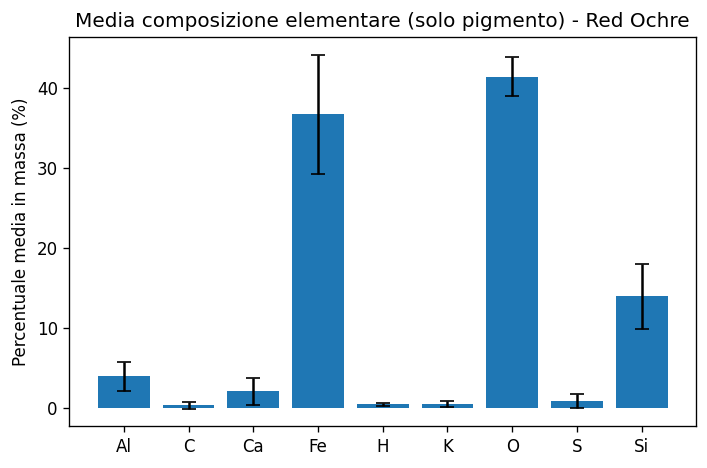

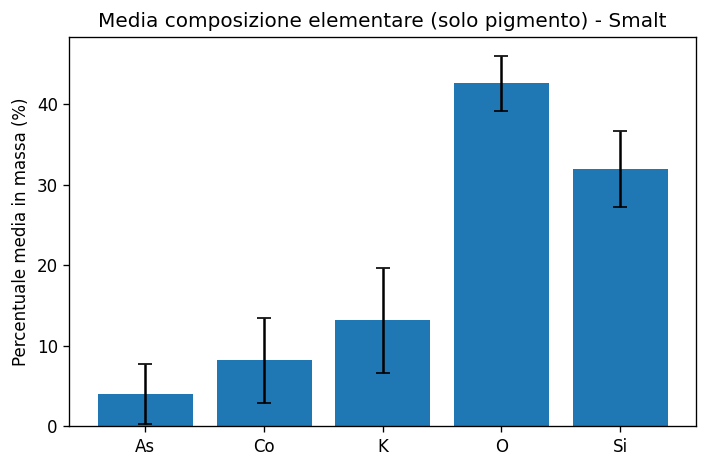

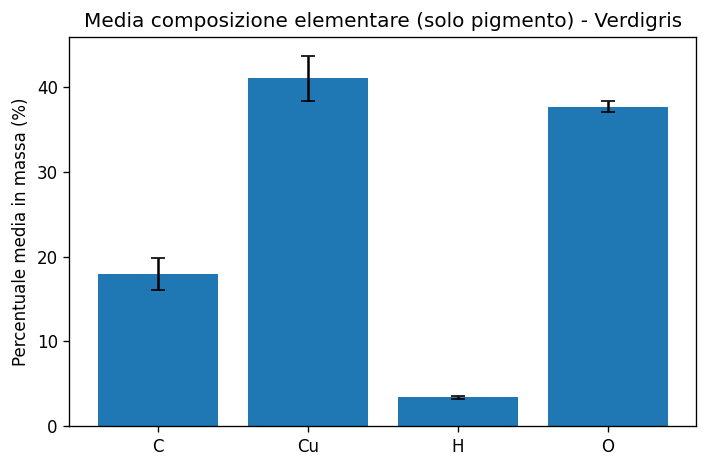

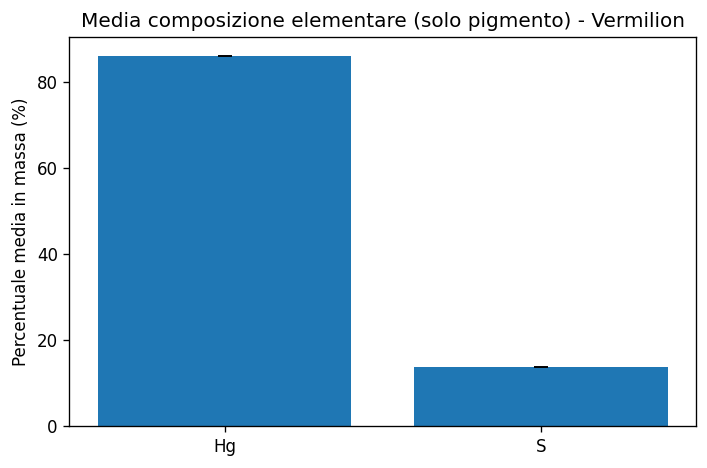

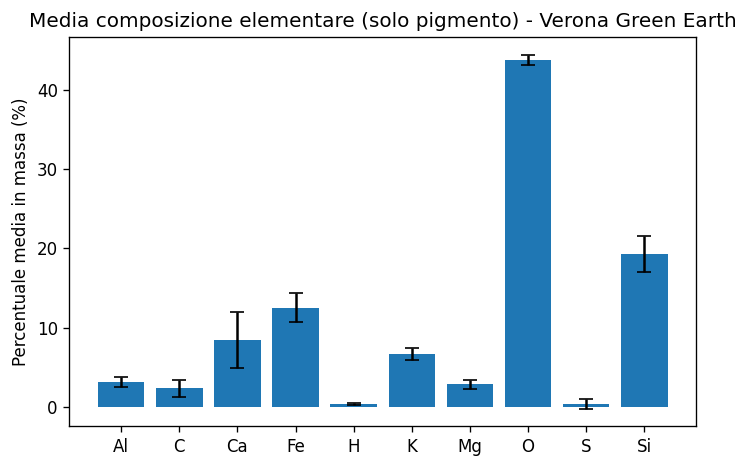

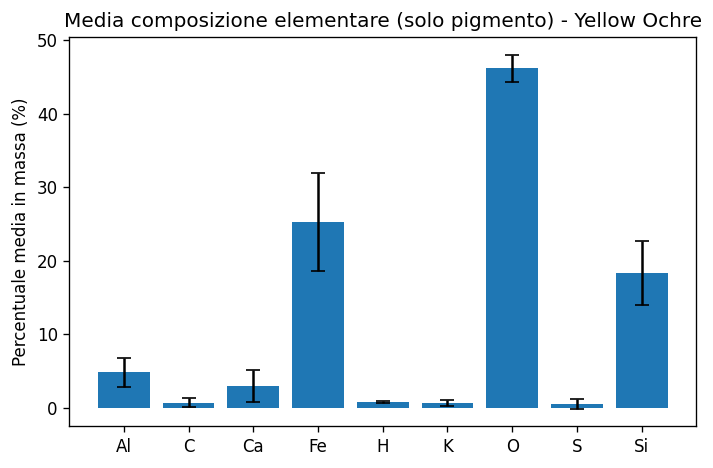

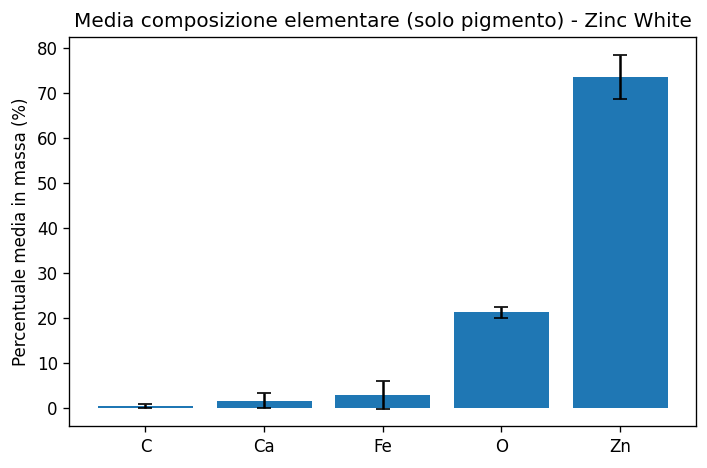

PDF salvato in: dataset_diagnostics_60000.pdf


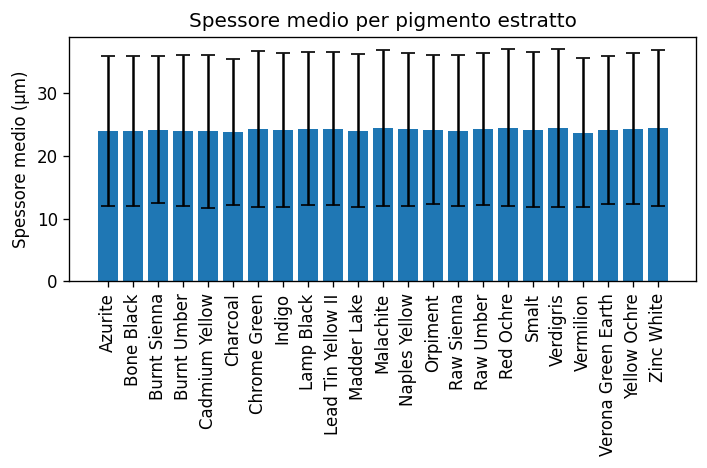

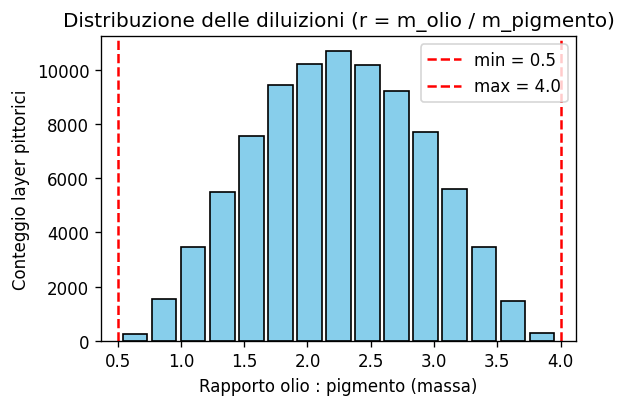

In [9]:
#Simulated painting genertion
from matplotlib.backends.backend_pdf import PdfPages

# numebr of layered structures to be simulated
N_SAMPLES=60000
PDF_OUT = f"dataset_diagnostics_{N_SAMPLES}.pdf"
pdf = PdfPages(PDF_OUT)

all_paintings = []
for pid in range(N_SAMPLES):
    layers = simulate_painting(pid, rng)
    all_paintings.append(layers)


# Control plots (only L1 and L2)

#total layers frequency
num_paint_layers_per_painting = []
for painting in all_paintings:
    n_paint = sum(1 for layer in painting if layer["type"] == "paint")
    num_paint_layers_per_painting.append(n_paint)

plt.figure(figsize=(4,3))
plt.hist(num_paint_layers_per_painting, bins=range(0, max(num_paint_layers_per_painting)+2), align="left", rwidth=0.8)
plt.xlabel("Numero di layer pittorici")
plt.ylabel("Conteggio layer")
plt.title(f"Distribuzione del numero di layer pittorici {N_SAMPLES}")
plt.xticks(range(0, max(num_paint_layers_per_painting)+2))
plt.tight_layout()
plt.show()

# Nominal pigment statistic

pigment_stats = {}

for painting in all_paintings:
    for layer in painting:
        if layer["type"] != "paint":
            continue

        name = layer["pigment_name"]
        components = pigment_data[name]["components"]
        phase_mass_fractions = layer["phase_mass_fractions"]

        # composizione SOLO pigmento
        elem_pigment_only = compute_elemental_composition_pigment_only(
            components,
            phase_mass_fractions
        )

        stats = pigment_stats.setdefault(
            name,
            {"thickness": [], "layer_index": [], "elem_pigment_only": []}
        )
        stats["thickness"].append(layer["thickness_um"])
        stats["layer_index"].append(layer["layer_index"])
        stats["elem_pigment_only"].append(elem_pigment_only)

pigments_used = sorted(pigment_stats.keys())
counts_per_pigment = [len(pigment_stats[name]["thickness"]) for name in pigments_used]
total_occurrences = sum(counts_per_pigment)

# Pigment occurances on the whole dataset 
#freq_per_pigment = [c / total_occurrences * 100.0 for c in counts_per_pigment]

plt.figure(figsize=(max(6, len(pigments_used)*0.25), 4))
x = np.arange(len(pigments_used))
plt.bar(x, counts_per_pigment)
plt.xticks(x, pigments_used, rotation=90)
plt.ylabel("Conteggi")
plt.title("Conteggi pigmenti estratti")
plt.tight_layout()
plt.show()

# Mean composition per pigment
pigment_mean_elem = {}  # pigment -> {el: mean_fraction}
pigment_std_elem  = {}  # pigment -> {el: std_fraction}
all_elements = set()

for name, d in pigment_stats.items():
    elem_dicts = d["elem_pigment_only"]
    if not elem_dicts:
        continue

    elems = set().union(*[e.keys() for e in elem_dicts])
    all_elements |= elems

    mean_comp = {}
    std_comp = {}
    for el in elems:
        vals = np.array([ed.get(el, 0.0) for ed in elem_dicts], dtype=float)
        mean_comp[el] = float(np.mean(vals))
        # σ (deviazione standard campionaria). Se vuoi quella "population" togli ddof=1
        std_comp[el]  = float(np.std(vals, ddof=1)) if len(vals) > 1 else 0.0

    pigment_mean_elem[name] = mean_comp
    pigment_std_elem[name]  = std_comp

all_elements = sorted(list(all_elements))


for name in sorted(pigment_mean_elem.keys()):
    mean_comp = pigment_mean_elem[name]
    std_comp  = pigment_std_elem[name]
    if not mean_comp:
        continue

    elements = sorted(mean_comp.keys())
    means = [mean_comp[el] * 100.0 for el in elements]  # %
    sigmas = [std_comp.get(el, 0.0) * 100.0 for el in elements]

    plt.figure(figsize=(6, 4))
    x = np.arange(len(elements))

    plt.bar(x, means, yerr=sigmas, capsize=4)
    plt.xticks(x, elements)
    plt.ylabel("Percentuale media in massa (%)")
    plt.title(f"Media composizione elementare (solo pigmento) - {name}")
    plt.tight_layout()
    pdf.savefig(plt.gcf(), bbox_inches="tight")
    plt.show()
    # se preferisci salvarli:
    # plt.savefig(f"mean_elem_pigment_only_{name.replace(' ', '_')}.png", dpi=150)
    # plt.close()


pdf.close()
print(f"PDF salvato in: {PDF_OUT}")
# Mean thickness per pigment
pigments_used = sorted(pigment_stats.keys())
mean_thickness_per_pigment = []
std_thickness_per_pigment  = [] 

for name in pigments_used:
    th_list = pigment_stats[name]["thickness"]
    th_arr = np.array(th_list, dtype=float)


    mean_thickness_per_pigment.append(np.mean(th_arr))

    if len(th_arr) > 1:
        std_thickness_per_pigment.append(np.std(th_arr, ddof=1))
    else:
        std_thickness_per_pigment.append(0.0)

plt.figure(figsize=(max(6, len(pigments_used)*0.25), 4))
x = np.arange(len(pigments_used))

plt.bar(x, mean_thickness_per_pigment, yerr=std_thickness_per_pigment, capsize=4)

plt.xticks(x, pigments_used, rotation=90)
plt.ylabel("Spessore medio (µm)")
plt.title("Spessore medio per pigmento estratto")
plt.tight_layout()
plt.show()


# ============================================================
#  cumulative binder-to-pigment ratio 
# ============================================================

all_ratios = [] 
for painting in all_paintings:
    for layer in painting:
        if layer["type"] != "paint":
            continue
        all_ratios.append(layer["oil_to_pig_ratio"])

plt.figure(figsize=(5,3.5))
plt.hist(all_ratios, bins=15, rwidth=0.85, color="skyblue", edgecolor="black")
plt.xlabel("Rapporto olio : pigmento (massa)")
plt.ylabel("Conteggio layer pittorici")
plt.title("Distribuzione delle diluizioni (r = m_olio / m_pigmento)")
plt.axvline(0.5, color="red", linestyle="--", label="min = 0.5")
plt.axvline(4.0, color="red", linestyle="--", label="max = 4.0")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
#L3 pigment occurance

from collections import Counter

def count_L3_samples(all_paintings):
    """
    Counts the frequency per pigment in L3
    """

    counts = Counter()

    # caso: singolo painting = lista di layer
    if isinstance(all_paintings, list) and len(all_paintings) > 0 and isinstance(all_paintings[0], dict):
        all_paintings = [all_paintings]

    for painting in all_paintings:
        for layer in painting:
            if layer.get("layer_index") == 3 or layer.get("type") == "support":
                name = layer.get("pigment_name", "UNKNOWN")
                counts[name] += 1
                break

    print("=== L3 / support counts ===")
    for k, v in counts.most_common():
        print(f"{k}: {v}")

    return counts

counts_L3 = count_L3_samples(all_paintings)

=== L3 / support counts ===
Titanium white: 49950
Gypsum: 20042
Calcite: 20035
Lead white: 9973


In [14]:
import time
from concurrent.futures import ProcessPoolExecutor, as_completed
from xrf_model import generate_spectrum_and_save
import os

# --------------------------
# XRF spectra simualtion
# --------------------------
json_path = "xrf_common_dict.json"
out_dir = "sim_batch_parallel_fix_new_pre_2"
os.makedirs(out_dir, exist_ok=True)
max_layers=3
N_SAMPLES = len(all_paintings)   
max_workers = 4                  #number of core
print(f"Userò {max_workers} worker per {N_SAMPLES} spettri")
print("Output in:", out_dir)
print()

# --------------------------
# Parallelizzation
# --------------------------

t_batch0 = time.time()

futures = []
start_times = {}  

with ProcessPoolExecutor(max_workers=max_workers) as ex:

    
    for i, painting in enumerate(all_paintings[:N_SAMPLES]):
        start_times[i] = time.time()
        print(f"[START] Spettro {i} alle {start_times[i]:.2f}")
        fut = ex.submit(
            generate_spectrum_and_save,
            i,
            painting,
            json_path,
            out_dir,
            E0,
            phi,
            A,
            d_geom,
            weights,
            0.0,      # x_min
            40000.0,  # x_max
            2048,     # x_points
            max_layers,        # max_layers
            False,    # do_plot
            False,    # add_noise_total
        )
        futures.append(fut)

   
    for fut in as_completed(futures):
        idx, path = fut.result()
        t_end = time.time()

        dt = t_end - start_times[idx]

        print(f"[END]   Spettro {idx} finito alle {t_end:.2f} "
              f"→ durata = {dt:.2f} s "
              f"→ file = {path}")

t_batch1 = time.time()

# --------------------------
# Total time
# --------------------------
print("\n-------------------------------------------")
print(f"Tempo totale batch = {t_batch1 - t_batch0:.2f} s")
print(f"Tempo medio per spettro (incluso parallel) = "
      f"{(t_batch1 - t_batch0)/N_SAMPLES:.2f} s")
print("-------------------------------------------")


Userò 4 worker per 11024 spettri
Output in: sim_batch_parallel_fix_new_pre_2

[START] Spettro 0 alle 1783666930.47
[START] Spettro 1 alle 1783666930.48
[START] Spettro 2 alle 1783666930.49
[START] Spettro 3 alle 1783666930.50
[START] Spettro 4 alle 1783666930.51
[START] Spettro 5 alle 1783666930.51
[START] Spettro 6 alle 1783666930.51
[START] Spettro 7 alle 1783666930.51
[START] Spettro 8 alle 1783666930.51
[START] Spettro 9 alle 1783666930.51
[START] Spettro 10 alle 1783666930.51
[START] Spettro 11 alle 1783666930.51
[START] Spettro 12 alle 1783666930.51
[START] Spettro 13 alle 1783666930.51
[START] Spettro 14 alle 1783666930.51
[START] Spettro 15 alle 1783666930.51
[START] Spettro 16 alle 1783666930.51
[START] Spettro 17 alle 1783666930.51
[START] Spettro 18 alle 1783666930.51
[START] Spettro 19 alle 1783666930.51
[START] Spettro 20 alle 1783666930.51
[START] Spettro 21 alle 1783666930.51
[START] Spettro 22 alle 1783666930.51
[START] Spettro 23 alle 1783666930.51
[START] Spettro 24 a

/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/xraydb/xraydb.py:731: UserWarning: Elam tables are unreliable for energies < 100 eV
  warn('Elam tables are unreliable for energies < 100 eV')
/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/xraydb/xraydb.py:731: UserWarning: Elam tables are unreliable for energies < 100 eV
  warn('Elam tables are unreliable for energies < 100 eV')
/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/xraydb/xraydb.py:731: UserWarning: Elam tables are unreliable for energies < 100 eV
  warn('Elam tables are unreliable for energies < 100 eV')
/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/xraydb/xraydb.py:731: UserWarning: Elam tables are unreliable for energies < 100 eV
  warn('Elam tables are unreliable for energies < 100 eV')


[END]   Spettro 3 finito alle 1783666935.61 → durata = 5.12 s → file = sim_batch_parallel_fix_new_pre_2/sim_00003.json
[END]   Spettro 4 finito alle 1783666938.68 → durata = 8.18 s → file = sim_batch_parallel_fix_new_pre_2/sim_00004.json
[END]   Spettro 2 finito alle 1783666939.41 → durata = 8.93 s → file = sim_batch_parallel_fix_new_pre_2/sim_00002.json
[END]   Spettro 1 finito alle 1783666939.94 → durata = 9.47 s → file = sim_batch_parallel_fix_new_pre_2/sim_00001.json
[END]   Spettro 0 finito alle 1783666941.29 → durata = 10.82 s → file = sim_batch_parallel_fix_new_pre_2/sim_00000.json
[END]   Spettro 7 finito alle 1783666942.08 → durata = 11.57 s → file = sim_batch_parallel_fix_new_pre_2/sim_00007.json
[END]   Spettro 9 finito alle 1783666942.96 → durata = 12.45 s → file = sim_batch_parallel_fix_new_pre_2/sim_00009.json
[END]   Spettro 8 finito alle 1783666944.61 → durata = 14.10 s → file = sim_batch_parallel_fix_new_pre_2/sim_00008.json
[END]   Spettro 10 finito alle 1783666944.93

/Users/ivanoliverio/XRF-sim/xrf_model.py:1342: RuntimeWarning: overflow encountered in exp
  M_val = (mu1l + mu1i)/(np.exp((mu1l + mu1i)*t1) - 1.0) * np.exp(-mubl*tb) * X(mu2l, mu1i, t1, t2)
/Users/ivanoliverio/XRF-sim/xrf_model.py:1323: RuntimeWarning: overflow encountered in exp
  pre  = np.exp((q - mu1j*np.sin(phi[1]))*d1_local
/Users/ivanoliverio/XRF-sim/xrf_model.py:1340: RuntimeWarning: invalid value encountered in scalar subtract
  return V(d1, d2) - V(d1, 0.0) - V(0.0, d2) + V(0.0, 0.0)


[END]   Spettro 3757 finito alle 1783670489.36 → durata = 3558.73 s → file = sim_batch_parallel_fix_new_pre_2/sim_03757.json
[END]   Spettro 3760 finito alle 1783670491.44 → durata = 3560.81 s → file = sim_batch_parallel_fix_new_pre_2/sim_03760.json
[END]   Spettro 3756 finito alle 1783670492.91 → durata = 3562.27 s → file = None
[END]   Spettro 3758 finito alle 1783670492.93 → durata = 3562.30 s → file = sim_batch_parallel_fix_new_pre_2/sim_03758.json
[END]   Spettro 3763 finito alle 1783670493.64 → durata = 3563.01 s → file = sim_batch_parallel_fix_new_pre_2/sim_03763.json
[END]   Spettro 3762 finito alle 1783670494.97 → durata = 3564.33 s → file = sim_batch_parallel_fix_new_pre_2/sim_03762.json
[END]   Spettro 3764 finito alle 1783670495.39 → durata = 3564.76 s → file = sim_batch_parallel_fix_new_pre_2/sim_03764.json
[END]   Spettro 3759 finito alle 1783670495.56 → durata = 3564.93 s → file = sim_batch_parallel_fix_new_pre_2/sim_03759.json
[END]   Spettro 3765 finito alle 1783670495

/Users/ivanoliverio/XRF-sim/xrf_model.py:1342: RuntimeWarning: overflow encountered in exp
  M_val = (mu1l + mu1i)/(np.exp((mu1l + mu1i)*t1) - 1.0) * np.exp(-mubl*tb) * X(mu2l, mu1i, t1, t2)
/Users/ivanoliverio/XRF-sim/xrf_model.py:1323: RuntimeWarning: overflow encountered in exp
  pre  = np.exp((q - mu1j*np.sin(phi[1]))*d1_local
/Users/ivanoliverio/XRF-sim/xrf_model.py:1340: RuntimeWarning: invalid value encountered in scalar subtract
  return V(d1, d2) - V(d1, 0.0) - V(0.0, d2) + V(0.0, 0.0)


[END]   Spettro 6937 finito alle 1783673647.72 → durata = 6717.02 s → file = sim_batch_parallel_fix_new_pre_2/sim_06937.json
[END]   Spettro 6935 finito alle 1783673651.94 → durata = 6721.24 s → file = sim_batch_parallel_fix_new_pre_2/sim_06935.json
[END]   Spettro 6938 finito alle 1783673652.68 → durata = 6721.98 s → file = None
[END]   Spettro 6936 finito alle 1783673652.75 → durata = 6722.04 s → file = sim_batch_parallel_fix_new_pre_2/sim_06936.json
[END]   Spettro 6940 finito alle 1783673653.80 → durata = 6723.09 s → file = sim_batch_parallel_fix_new_pre_2/sim_06940.json
[END]   Spettro 6939 finito alle 1783673655.72 → durata = 6725.01 s → file = sim_batch_parallel_fix_new_pre_2/sim_06939.json
[END]   Spettro 6942 finito alle 1783673655.74 → durata = 6725.04 s → file = sim_batch_parallel_fix_new_pre_2/sim_06942.json
[END]   Spettro 6943 finito alle 1783673656.13 → durata = 6725.43 s → file = sim_batch_parallel_fix_new_pre_2/sim_06943.json
[END]   Spettro 6941 finito alle 1783673656

In [10]:
import pandas as pd
import numpy as np


def sample_elemental_compositions(
    pigment_name,
    n_samples=10000,
    seed=None,
):
    """
    Estrae n_samples configurazioni casuali del pigmento
    usando ESATTAMENTE la pipeline del simulatore.

    Ritorna un DataFrame.
    """

    rng = np.random.default_rng(seed)

    rows = []

    for i in range(n_samples):

        layer = simulate_paint_layer(
            layer_index=1,
            rng=rng,
            pigment_name=pigment_name,
        )

        comp = layer["elemental_composition"]

        rows.append({

            "Cu": comp.get("Cu",0.0),
            "Fe": comp.get("Fe",0.0),
            "Si": comp.get("Si",0.0),
            "Ca": comp.get("Ca",0.0),

            "oil_fraction": layer["m_oil"],
            "pigment_fraction": layer["m_pig"],
            "rho": layer["rho_layer_g_cm3"],
            "thickness": layer["thickness_um"]

        })

    return pd.DataFrame(rows)

In [11]:
df_az = sample_elemental_compositions(
    "Azurite",
    n_samples=10000,
    seed=1,
)

df_ml = sample_elemental_compositions(
    "Malachite",
    n_samples=10000,
    seed=2,
)

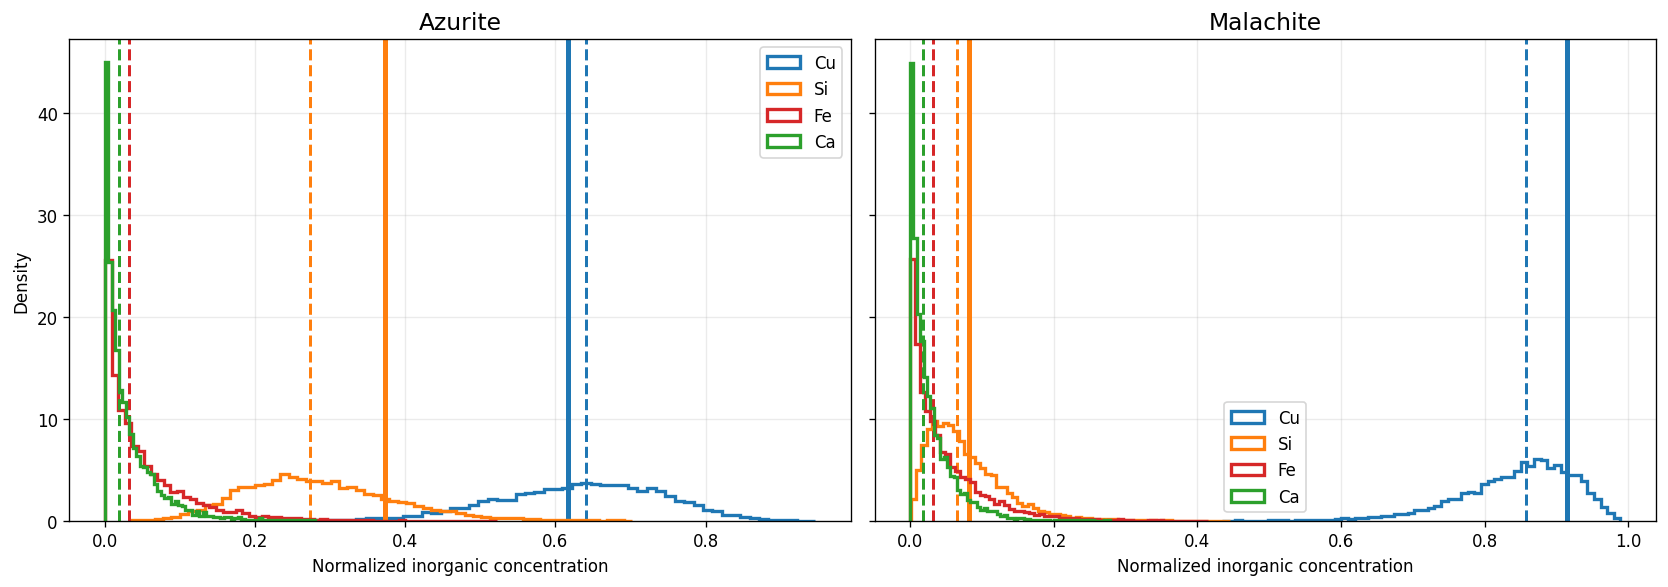

In [12]:
# ============================================================
# NORMALIZZAZIONE INORGANICA
# ============================================================

elements = ["Cu", "Si", "Fe", "Ca"]

for df in [df_az, df_ml]:

    s = df[elements].sum(axis=1)

    for el in elements:
        df[el + "_norm"] = df[el] / s

import matplotlib.pyplot as plt
import numpy as np

elements = ["Cu", "Si", "Fe", "Ca"]

import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# Normalizzazione alla sola parte inorganica
# ============================================================

elements = ["Cu", "Si", "Fe", "Ca"]

for df in [df_az, df_ml]:

    s = df[elements].sum(axis=1)

    for el in elements:
        df[el + "_norm"] = df[el] / s

# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14,5), sharey=True)

colors = {
    "Cu":"tab:blue",
    "Si":"tab:orange",
    "Fe":"tab:red",
    "Ca":"tab:green",
}

titles = ["Azurite", "Malachite"]
dfs = [df_az, df_ml]

for ax, df, title in zip(axes, dfs, titles):

    for el in elements:

        values = df[el + "_norm"]

        ax.hist(
            values,
            bins=60,
            density=True,
            histtype="step",
            linewidth=2,
            color=colors[el],
            label=el,
        )

        med = np.median(values)

                

        ax.axvline(
            med,
            color=colors[el],
            linestyle="--",
            linewidth=1.8,
        )

        # -----------------------------
        # Valori sperimentali PyMca
        # -----------------------------
        if title == "Azurite":

            if el == "Cu":
                ax.axvline(
                    0.617,
                    color=colors[el],
                    linestyle="-",
                    linewidth=3,
                )

            elif el == "Si":
                ax.axvline(
                    0.373,
                    color=colors[el],
                    linestyle="-",
                    linewidth=3,
                )

        elif title == "Malachite":

            if el == "Cu":
                ax.axvline(
                    0.915,
                    color=colors[el],
                    linestyle="-",
                    linewidth=3,
                )

            elif el == "Si":
                ax.axvline(
                    0.0813,
                    color=colors[el],
                    linestyle="-",
                    linewidth=3,
                )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Normalized inorganic concentration")
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Density")

plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# PRIMARY FLUORESCENCE RATIOS
# ============================================================

import numpy as np
import xraydb
import numpy as np
import xraydb

# ============================================================
# Rh Kα energy (media pesata Ka1+Ka2)
# ============================================================

def effective_ka_energy_eV_fast(element):

    lines = xraydb.xray_lines(element)

    energies = []
    intensities = []

    for name, line in lines.items():

        if name.lower().startswith("ka"):

            energies.append(line.energy)
            intensities.append(line.intensity)

    energies = np.asarray(energies, float)
    intensities = np.asarray(intensities, float)

    return np.sum(energies * intensities) / np.sum(intensities)


E_RH = effective_ka_energy_eV_fast("Rh")


# ============================================================
# emission energies
# ============================================================

E_LINES = {

    "Si": effective_ka_energy_eV_fast("Si"),
    "Fe": effective_ka_energy_eV_fast("Fe"),
    "Cu": effective_ka_energy_eV_fast("Cu"),

}


# ============================================================
# photoelectric excitation
# ============================================================

EXCITATION = {}

for el in ["Si","Fe","Cu"]:

    edge = xraydb.xray_edge(el,"K")

    if E_RH > edge.energy:

        EXCITATION[el] = xraydb.mu_elam(
            el,
            E_RH,
            kind="photo"
        )

    else:

        EXCITATION[el] = 0.0


# ============================================================
# geometry
# (usa gli stessi angoli del simulatore)
# ============================================================

phi = (
    np.deg2rad(68.0),
    np.deg2rad(52.0),
)
# ------------------------------------------------------------
# mixture attenuation
# ------------------------------------------------------------

def mu_mix_from_row(row, energy_eV, family):

    # frazioni elementari già presenti
    Cu = row["Cu"]
    Si = row["Si"]
    Fe = row["Fe"]
    Ca = row["Ca"]

    # resto della massa = matrice leggera
    light = max(0.0, 1.0 - Cu - Si - Fe - Ca)

    # composizione media della matrice
    # (C+O+H dei carbonati + O di quarzo/calcite)

    mu = 0.0

    mu += Cu * xraydb.mu_elam("Cu", energy_eV, kind="total")
    mu += Si * xraydb.mu_elam("Si", energy_eV, kind="total")
    mu += Fe * xraydb.mu_elam("Fe", energy_eV, kind="total")
    mu += Ca * xraydb.mu_elam("Ca", energy_eV, kind="total")

    # matrice leggera approssimata
    mu += 0.55 * light * xraydb.mu_elam("O", energy_eV, kind="total")
    mu += 0.35 * light * xraydb.mu_elam("C", energy_eV, kind="total")
    mu += 0.10 * light * xraydb.mu_elam("H", energy_eV, kind="total")

    return mu


# ------------------------------------------------------------
# primary intensity
# ------------------------------------------------------------
E_RH=20.2
def primary_intensity(row, element):

    C = row[element]

    if C <= 0:
        return 0.0

    mu_inc = mu_mix_from_row(
        row,
        E_RH,
        None,
    )

    mu_out = mu_mix_from_row(
        row,
        E_LINES[element],
        None,
    )

    chi = (

        mu_inc / np.sin(phi[0])

        +

        mu_out / np.sin(phi[1])

    )

    rho_t = row["rho"] * row["thickness"] * 1e-4

    sensitivity = (

        EXCITATION[element]

        *

        (1.0 - np.exp(-chi * rho_t))

        / chi

    )

    return C * sensitivity


# ------------------------------------------------------------
# dataframe
# ------------------------------------------------------------

from tqdm.auto import tqdm

def add_primary_ratios(df):

    df = df.copy()

    ICu = np.zeros(len(df))
    ISi = np.zeros(len(df))
    IFe = np.zeros(len(df))

    for i, (_, row) in enumerate(
        tqdm(
            df.iterrows(),
            total=len(df),
            desc="Primary fluorescence"
        )
    ):

        ICu[i] = primary_intensity(row, "Cu")
        ISi[i] = primary_intensity(row, "Si")
        IFe[i] = primary_intensity(row, "Fe")

    df["ICu"] = ICu
    df["ISi"] = ISi
    df["IFe"] = IFe

    df["ISi_ICu"] = df["ISi"] / df["ICu"]
    df["IFe_ICu"] = df["IFe"] / df["ICu"]

    return df


# ============================================================
# APPLY
# ============================================================

df_az = add_primary_ratios(df_az)
df_ml = add_primary_ratios(df_ml)

/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Primary fluorescence:   0%|                           | 0/10000 [00:00<?, ?it/s]/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/xraydb/xraydb.py:731: UserWarning: Elam tables are unreliable for energies < 100 eV
  warn('Elam tables are unreliable for energies < 100 eV')
Primary fluorescence:   0%|                           | 0/10000 [00:00<?, ?it/s]/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/xraydb/xraydb.py:731: UserWarning: Elam tables are unreliable for energies < 100 eV
  warn('Elam tables are unreliable for energies < 100 eV')
Primary fluorescence: 100%|██████████████| 10000/10000 [00:52<00:00, 189.02it/s]


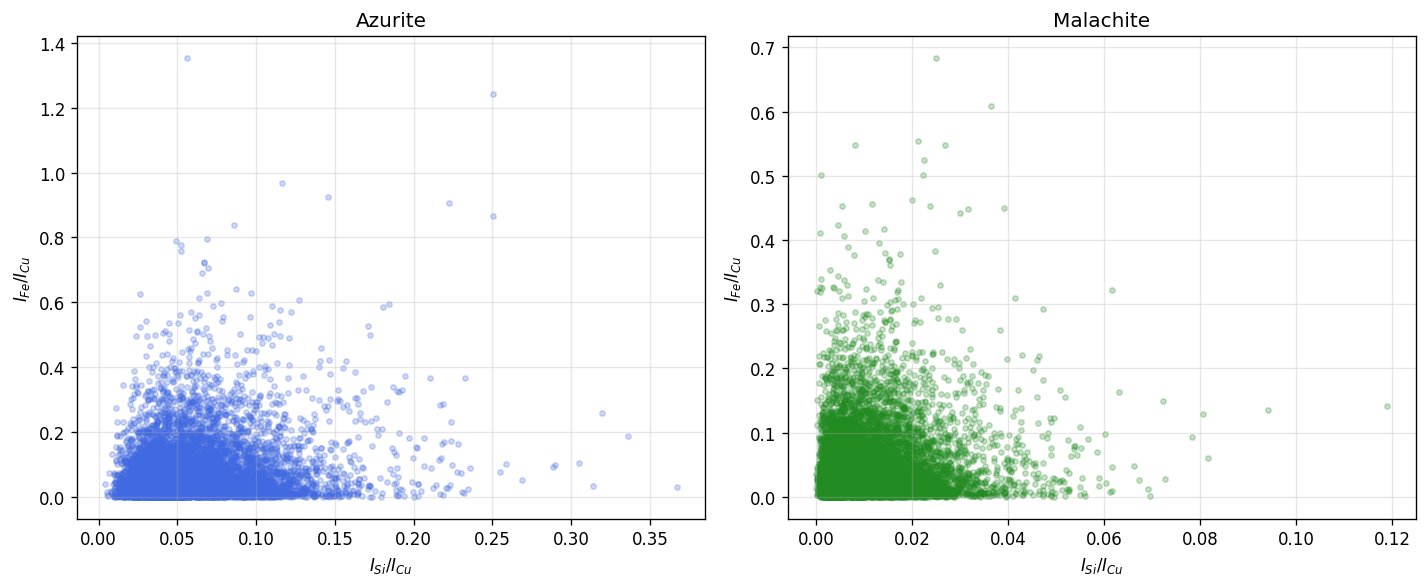

In [14]:
import matplotlib.pyplot as plt


def plot_primary_ratio_biplots(
    df_az,
    df_ml,
    az_point=None,
    ml_point=None,
):

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # ==========================================================
    # AZURITE
    # ==========================================================

    ax[0].scatter(
        df_az["ISi_ICu"],
        df_az["IFe_ICu"],
        s=10,
        alpha=0.25,
        color="royalblue",
    )

    if az_point is not None:

        ax[0].scatter(
            az_point[0],
            az_point[1],
            marker="*",
            s=250,
            color="red",
            edgecolor="k",
            linewidth=1,
            label="PyMca",
        )

        ax[0].legend()

    ax[0].set_title("Azurite")
    ax[0].set_xlabel(r"$I_{Si}/I_{Cu}$")
    ax[0].set_ylabel(r"$I_{Fe}/I_{Cu}$")
    ax[0].grid(alpha=0.3)

    # ==========================================================
    # MALACHITE
    # ==========================================================

    ax[1].scatter(
        df_ml["ISi_ICu"],
        df_ml["IFe_ICu"],
        s=10,
        alpha=0.25,
        color="forestgreen",
    )

    if ml_point is not None:

        ax[1].scatter(
            ml_point[0],
            ml_point[1],
            marker="*",
            s=250,
            color="red",
            edgecolor="k",
            linewidth=1,
            label="PyMca",
        )

        ax[1].legend()

    ax[1].set_title("Malachite")
    ax[1].set_xlabel(r"$I_{Si}/I_{Cu}$")
    ax[1].set_ylabel(r"$I_{Fe}/I_{Cu}$")
    ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_primary_ratio_biplots(
    df_az,
    df_ml,
)

In [15]:
# ============================================================
# GENERATE OIL DILUTIONS
# ============================================================

import numpy as np

rng = np.random.default_rng(12345)

# composizione dell'olio
OIL = {
    "C":0.77,
    "H":0.12,
    "O":0.11,
}

BINDER_CHOICES = [
    1.0,   # 1:1
    2.0,   # 2:1
    2.5,   # 2.5:1
]


def dilute_with_linseed_oil(df):

    df_new = df.copy()

    binder = rng.choice(
        BINDER_CHOICES,
        size=len(df_new),
    )

    df_new["binder_ratio"] = binder

    for i,row in df_new.iterrows():

        r = row["binder_ratio"]

        m_pig = 1.0/(1.0+r)
        m_oil = r/(1.0+r)

        # -------------------------
        # elementi del pigmento
        # -------------------------

        Cu = row["Cu"]*m_pig
        Si = row["Si"]*m_pig
        Fe = row["Fe"]*m_pig
        Ca = row["Ca"]*m_pig

        # -------------------------
        # olio
        # -------------------------

        C = row.get("C",0.0)*m_pig + m_oil*OIL["C"]
        O = row.get("O",0.0)*m_pig + m_oil*OIL["O"]
        H = row.get("H",0.0)*m_pig + m_oil*OIL["H"]

        # normalizzazione numerica

        total = (
            Cu+Si+Fe+Ca+C+O+H
        )

        df_new.at[i,"Cu"] = Cu/total
        df_new.at[i,"Si"] = Si/total
        df_new.at[i,"Fe"] = Fe/total
        df_new.at[i,"Ca"] = Ca/total

        df_new.at[i,"C"] = C/total
        df_new.at[i,"O"] = O/total
        df_new.at[i,"H"] = H/total

    # ricalcola intensità e rapporti
    df_new = add_primary_ratios(df_new)

    return df_new


# ============================================================
# APPLY
# ============================================================

df_az_oil = dilute_with_linseed_oil(df_az)

df_ml_oil = dilute_with_linseed_oil(df_ml)

Primary fluorescence:   0%|                           | 0/10000 [00:00<?, ?it/s]/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/xraydb/xraydb.py:731: UserWarning: Elam tables are unreliable for energies < 100 eV
  warn('Elam tables are unreliable for energies < 100 eV')
Primary fluorescence:   0%|                           | 0/10000 [00:00<?, ?it/s]/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/xraydb/xraydb.py:731: UserWarning: Elam tables are unreliable for energies < 100 eV
  warn('Elam tables are unreliable for energies < 100 eV')
Primary fluorescence: 100%|██████████████| 10000/10000 [00:52<00:00, 189.47it/s]


In [16]:
import matplotlib.pyplot as plt


def plot_primary_ratio_biplots_oil(
    df_az,
    df_ml,
    az_point=None,
    ml_point=None,
):

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))

    # ==========================================================
    # AZURITE
    # ==========================================================

    ax[0].scatter(
        df_az["ISi_ICu"],
        df_az["IFe_ICu"],
        s=12,
        alpha=0.25,
        color="royalblue",
        label="Simulated"
    )

    if az_point is not None:

        ax[0].scatter(
            az_point[0],
            az_point[1],
            marker="*",
            s=260,
            color="red",
            edgecolor="k",
            linewidth=1,
            label="Experimental",
            zorder=10,
        )

    # mediana simulazione
    ax[0].scatter(
        df_az["ISi_ICu"].median(),
        df_az["IFe_ICu"].median(),
        marker="X",
        s=180,
        color="black",
        label="Median",
        zorder=9,
    )

    ax[0].set_title("Azurite")
    ax[0].set_xlabel(r"$I_{SiK\alpha}/I_{CuK\alpha}$")
    ax[0].set_ylabel(r"$I_{FeK\alpha}/I_{CuK\alpha}$")
    ax[0].grid(alpha=0.3)
    ax[0].legend()


    # ==========================================================
    # MALACHITE
    # ==========================================================

    ax[1].scatter(
        df_ml["ISi_ICu"],
        df_ml["IFe_ICu"],
        s=12,
        alpha=0.25,
        color="forestgreen",
        label="Simulated"
    )

    if ml_point is not None:

        ax[1].scatter(
            ml_point[0],
            ml_point[1],
            marker="*",
            s=260,
            color="red",
            edgecolor="k",
            linewidth=1,
            label="Experimental",
            zorder=10,
        )

    ax[1].scatter(
        df_ml["ISi_ICu"].median(),
        df_ml["IFe_ICu"].median(),
        marker="X",
        s=180,
        color="black",
        label="Median",
        zorder=9,
    )

    ax[1].set_title("Malachite")
    ax[1].set_xlabel(r"$I_{SiK\alpha}/I_{CuK\alpha}$")
    ax[1].set_ylabel(r"$I_{FeK\alpha}/I_{CuK\alpha}$")
    ax[1].grid(alpha=0.3)
    ax[1].legend()

    plt.tight_layout()
    plt.show()

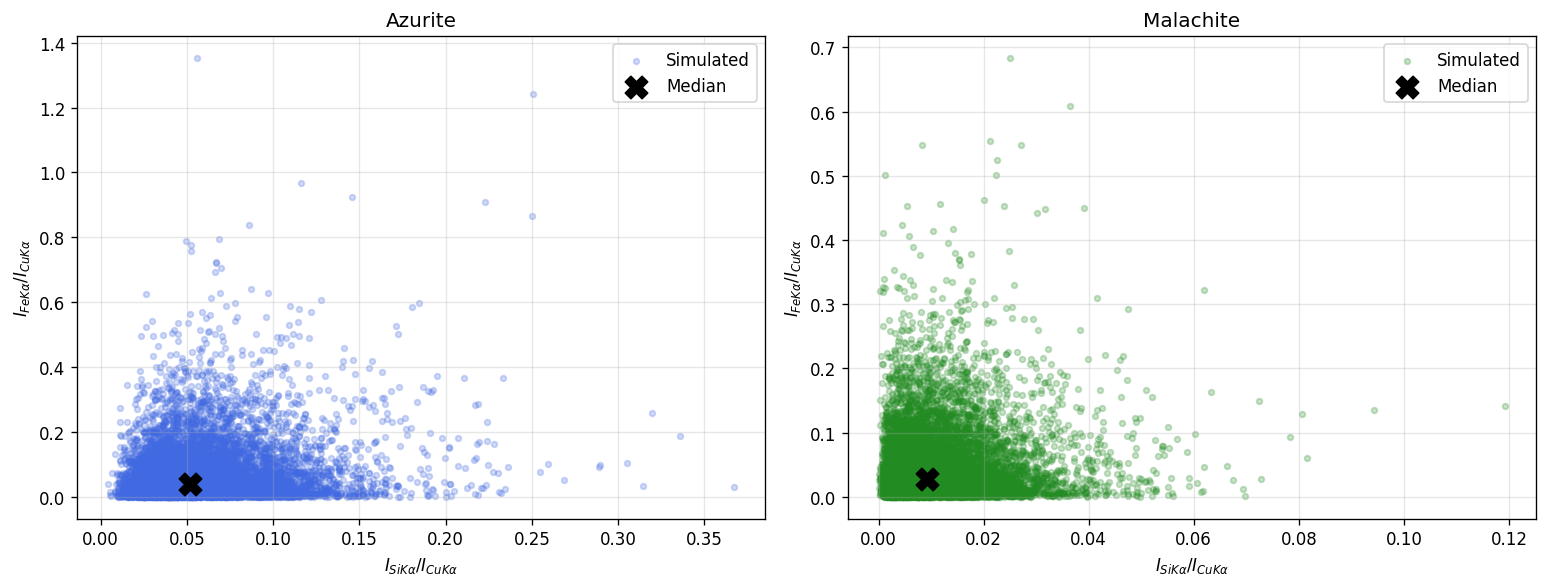

In [18]:
plot_primary_ratio_biplots_oil(
    df_az_oil,
    df_ml_oil,
    #az_point=(AZ_SiCu, AZ_FeCu),
    #ml_point=(ML_SiCu, ML_FeCu),
)

File trovati: 143724

FILES WITH Cu
Totali : 143724
Con Cu : 0

L1: 0
L2: 0
L3: 0


/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/ivanoliverio/xrf-env/lib/python3.14/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


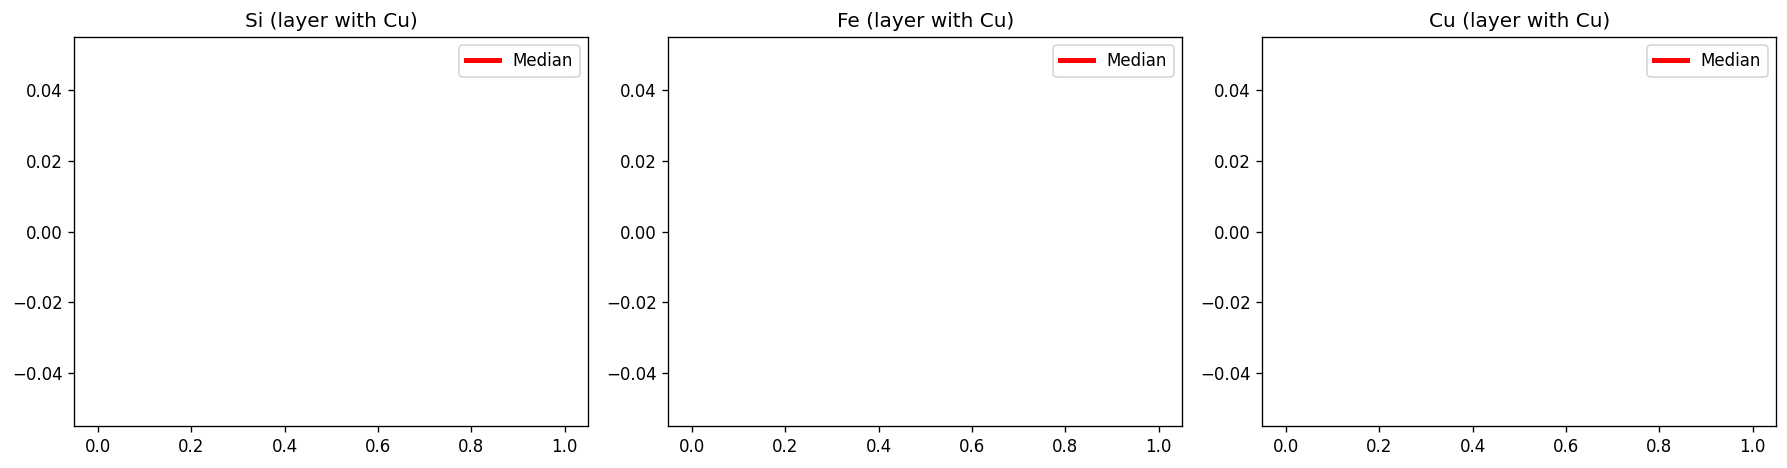

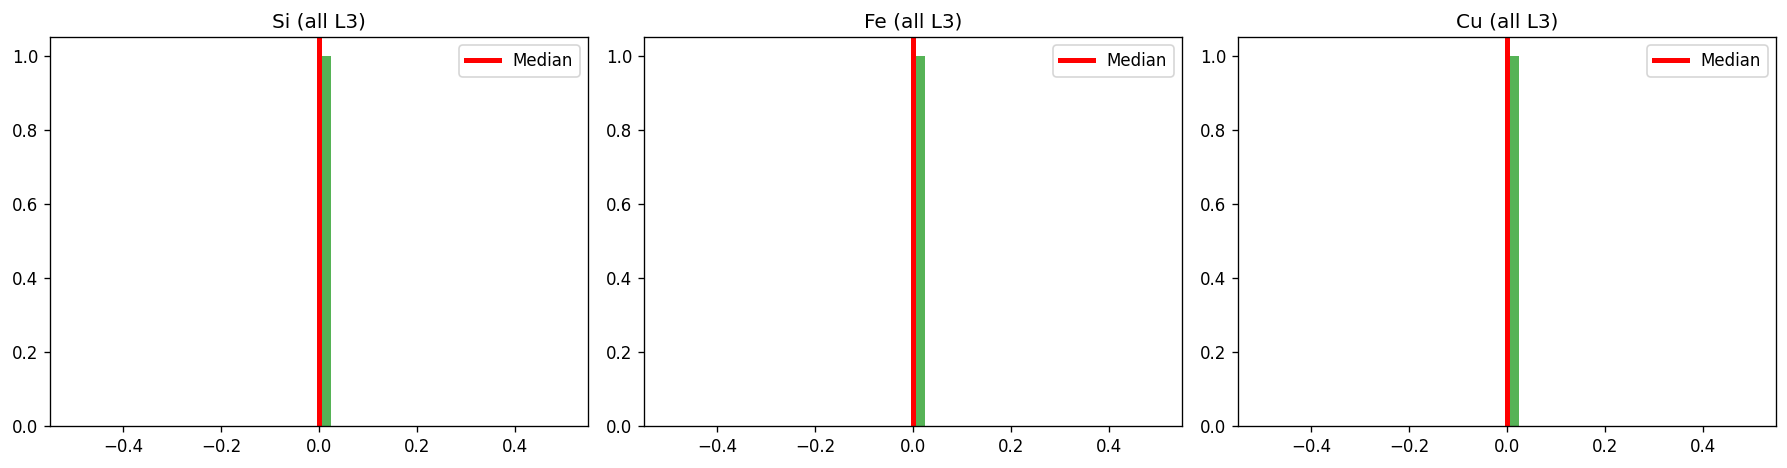

In [21]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CARTELLA
# ============================================================

ROOT = Path("cartella_air14cm")

files = sorted(ROOT.glob("*.json"))

print(f"File trovati: {len(files)}")

# ============================================================
# STATISTICHE
# ============================================================

n_with_cu = 0

layer_counter = {
    "L1":0,
    "L2":0,
    "L3":0,
}

cu_layer_data = {
    "Si":[],
    "Fe":[],
    "Cu":[]
}

l3_data = {
    "Si":[],
    "Fe":[],
    "Cu":[]
}

# ============================================================
# LOOP
# ============================================================

comp = data["labels"]["composition"]

# -------------------------
# tutti gli L3
# -------------------------

if "layer_3" in comp:

    c = comp["layer_3"]

    l3_data["Si"].append(c.get("Si",0))
    l3_data["Fe"].append(c.get("Fe",0))
    l3_data["Cu"].append(c.get("Cu",0))


# -------------------------
# primo layer con Cu
# -------------------------

for lname in ["layer_1","layer_2","layer_3"]:

    if lname not in comp:
        continue

    c = comp[lname]

    if c.get("Cu",0) > 0:

        n_with_cu += 1

        if lname=="layer_1":
            layer_counter["L1"] += 1
        elif lname=="layer_2":
            layer_counter["L2"] += 1
        else:
            layer_counter["L3"] += 1

        cu_layer_data["Si"].append(c.get("Si",0))
        cu_layer_data["Fe"].append(c.get("Fe",0))
        cu_layer_data["Cu"].append(c.get("Cu",0))

        break

# ============================================================
# REPORT
# ============================================================

print()
print("="*60)
print("FILES WITH Cu")
print("="*60)

print("Totali :", len(files))
print("Con Cu :", n_with_cu)

print()

for k,v in layer_counter.items():
    print(f"{k}: {v}")

# ============================================================
# HIST Cu layer
# ============================================================

fig,ax=plt.subplots(1,3,figsize=(15,4))

for i,el in enumerate(["Si","Fe","Cu"]):

    ax[i].hist(
        cu_layer_data[el],
        bins=40,
        alpha=0.8,
    )

    ax[i].axvline(
        np.median(cu_layer_data[el]),
        color="red",
        lw=3,
        label="Median"
    )

    ax[i].set_title(f"{el} (layer with Cu)")
    ax[i].legend()

plt.tight_layout()
plt.show()

# ============================================================
# HIST L3
# ============================================================

fig,ax=plt.subplots(1,3,figsize=(15,4))

for i,el in enumerate(["Si","Fe","Cu"]):

    ax[i].hist(
        l3_data[el],
        bins=40,
        alpha=0.8,
        color="tab:green",
    )

    ax[i].axvline(
        np.median(l3_data[el]),
        color="red",
        lw=3,
        label="Median"
    )

    ax[i].set_title(f"{el} (all L3)")
    ax[i].legend()

plt.tight_layout()
plt.show()